# Improvements

Notebook 04 found these issues in the six log-return models:

* **Forecast accuracy:** none of the six networks beat the naive or the random walk with drift baselines.
* **Model selection:** the six validation losses differ only in the third decimal, and the selected model (lowest validation loss) ranked fourth of six on the test set.
* **Bias:** every network predicts a fall on most days, while the price rose on 55% of the test days. The networks see **scaled price levels**, and the test prices lie far above the training range, so they receive input values they never saw during training.

CRISP-DM is iterative, so this notebook goes back twice, each time with one change to the selected model:

1. **Data preparation: stationary inputs.** Replace the closing price (and volume) inputs with the daily **log return** (and the log volume and its daily change). These series do not drift with the price level. The selected configuration is retrained with them and compared with the original.
2. **Modeling: hyperparameter tuning.** KerasTuner searches units, dropout, learning rate and batch size (and the kernel size if the model is a CNN) for the better of the two versions, using the validation set only.

Every choice between versions uses **validation RMSE in dollars**, a rule set before looking at any result. The test set only reports the outcome. The six models from notebooks 03 and 04 are not retrained: the new runs are saved in their own folders (`_returns` and `_tuned` suffixes), so the earlier results stay as they are and serve as the reference.

Training the new version takes seconds; the tuning search takes about 7 minutes on a laptop CPU. Set `RETRAIN = False` in `config.py` to reload the saved runs and search instead.

[`docs/02_time_series_concepts.md`](../docs/02_time_series_concepts.md) | [`docs/03_deep_learning_models.md`](../docs/03_deep_learning_models.md)

In [ ]:
""" Notebook setup: make the project's modules (config.py, src/) importable """
import os
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
if "TF_CPP_MIN_LOG_LEVEL" not in os.environ:
    os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # hide TensorFlow info/warning logs
if os.name == "nt":  # Windows: expose the conda env's CUDA/cuDNN DLLs so TensorFlow can find the GPU
    os.environ["PATH"] = os.path.join(sys.prefix, "Library", "bin") + os.pathsep + os.environ["PATH"]


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config
from src.data_loader import load_stock_data
from src.evaluate import comparison_table, predict_split
from src.features import get_feature_columns
from src.notebook import show_source
from src.predict import load_artifacts, predict_next_day, simulate_recent
from src.preprocessing import load_prepared_data
from src.train import train_or_load
from src.tuning import TunedModel, run_tuning, best_hparams_from
from src import plotting

plotting.set_plot_style()

## The selected model
The run with the lowest validation loss, read from `artifacts/metrics.csv` (written by notebook 04). It is reloaded, not retrained.

In [ ]:
metrics = pd.read_csv(config.METRICS_PATH, index_col=0)
selected_run = metrics[metrics["kind"] == "model"]["val_loss"].idxmin()
selected_model_name = metrics.loc[selected_run, "model"]
selected_use_volume = metrics.loc[selected_run, "features"] == "close + volume"

selected = train_or_load(selected_model_name, selected_use_volume, retrain=False)
print("Selected model:", selected_run, "| architecture:", selected_model_name, "| volume:", selected_use_volume,
      "| inputs:", selected.data.feature_columns)

lstm_close_volume        reloaded (13 epochs, best epoch 3, val_loss 0.3841)
Selected model: lstm_close_volume | architecture: lstm | volume: True | inputs: ['Close', 'Volume']


## Iteration 1: stationary inputs (data preparation)
The scaler learns the mean and standard deviation of the inputs from the training period only (notebook 02). That is correct, but it has a consequence for a price that keeps rising: later prices are scaled to values the network never saw during training. The table below shows the range of the scaled first input of each split, for the original inputs and for the new ones.

`get_feature_columns` in `src/features.py` chooses the input columns. With `input_mode="returns"` the price-only runs see the daily log return, and the price + volume runs also see the log volume and its daily change. The target (tomorrow's log return), the lookback, the split and the scaling steps are unchanged.

In [ ]:
show_source(get_feature_columns)

returns_data = load_prepared_data(use_volume=selected_use_volume, input_mode="returns", verbose=False)
rows = []
for label, data in {"levels (selected model)": selected.data, "returns (this iteration)": returns_data}.items():
    for split, s in data.splits.items():
        rows.append({"inputs": label, "split": split, "first input": data.feature_columns[0],
                     "min (scaled)": s.X[:, :, 0].min(), "max (scaled)": s.X[:, :, 0].max()})
pd.DataFrame(rows).set_index(["inputs", "split"]).round(2)


<details>
<summary>View implementation of <code>get_feature_columns</code></summary>

```python
def get_feature_columns(use_volume: bool, input_mode: str = config.INPUT_MODE) -> list:
    """
    Return the list of input columns.

    input_mode="levels"  (the six models)
        use_volume=False -> ["Close"]                                  (price only)
        use_volume=True  -> ["Close", "Volume"]                        (price + volume)
    input_mode="returns" (notebook 06, stationary inputs)
        use_volume=False -> ["log_return"]
        use_volume=True  -> ["log_return", "log_volume", "volume_change"]
    """
    if input_mode == "levels":
        price, volume = PRICE_FEATURES, VOLUME_FEATURES
    elif input_mode == "returns":
        price, volume = RETURN_PRICE_FEATURES, RETURN_VOLUME_FEATURES
    else:
        raise ValueError(f"Unknown input_mode '{input_mode}'. Use 'levels' or 'returns'.")
    columns = price.copy()
    if use_volume:
        columns += volume
    return columns

```

</details>


first input  min (scaled)  max (scaled)
inputs                   split                                        
levels (selected model)  train       Close         -0.94          3.45
                         val         Close          2.55          4.73
                         test        Close          3.76          9.06
returns (this iteration) train  log_return         -7.82          6.32
                         val    log_return         -3.47          4.74
                         test   log_return         -5.53          7.98

The same architecture, feature set and training settings as the selected model, with the new inputs. The run is saved as `<selected run>_returns`.

lstm_close_volume_returns  40 epochs, best epoch  30, val_loss 0.3880, 42s
Inputs: ['log_return', 'log_volume', 'volume_change']


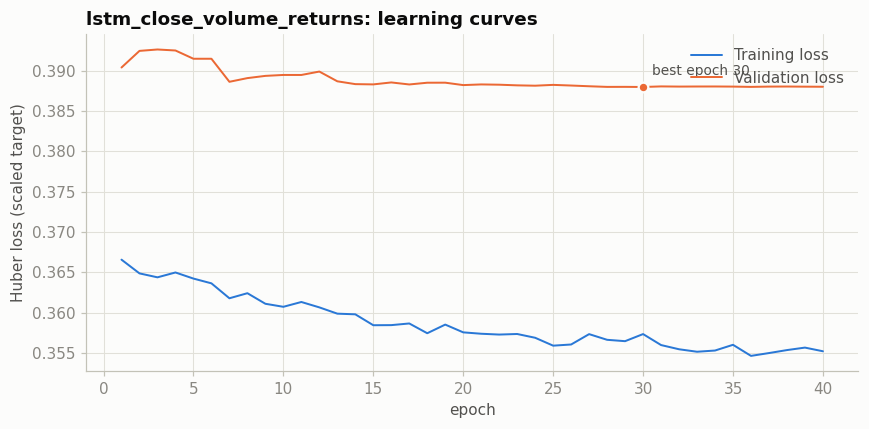

In [ ]:
returns = train_or_load(selected_model_name, selected_use_volume, input_mode="returns")
returns_run = returns.metadata["run_name"]
print("Inputs:", returns.data.feature_columns)
plotting.plot_history(returns.history, f"{returns_run}: learning curves")
plt.show()

### Choosing between the two versions
Validation RMSE in dollars decides which version goes on to the tuning step.

In [ ]:
ITERATION_1 = {selected_run: selected, returns_run: returns}
iteration1_validation = comparison_table(ITERATION_1, split="val")
iteration1_best = iteration1_validation[iteration1_validation["kind"] == "model"]["RMSE"].idxmin()
best_result = ITERATION_1[iteration1_best]
best_input_mode = best_result.metadata.get("input_mode", "levels")
print("Validation set, in dollars:")
display(iteration1_validation.round(4))
print("Best by validation RMSE:", iteration1_best, "| inputs:", best_input_mode)

Validation set, in dollars:


,kind,MAE,RMSE,MAPE_%,DirAcc_%
run,,,,,
lstm_close_volume,model,2.0414,2.7048,1.2972,52.6984
baseline: naive (tomorrow = today),baseline,2.0512,2.7110,1.3029,NaN
baseline: random walk + drift,baseline,2.0540,2.7147,1.3049,51.1111
lstm_close_volume_returns,model,2.0632,2.7175,1.3099,50.6349
baseline: 5-day moving average,baseline,3.1819,3.9911,2.0092,49.0476


Best by validation RMSE: lstm_close_volume | inputs: levels


## Iteration 2: hyperparameter tuning (modeling)
The search space is defined in `src/tuning.py`. Each of the 20 trials trains the winner of iteration 1 with the same callbacks as notebook 03 and is scored by its best validation loss. The best combination is then retrained with `train_model`, so it is saved (`_tuned` suffix) and evaluated like the other runs.

In [ ]:
show_source(TunedModel)
show_source(run_tuning)


<details>
<summary>View implementation of <code>TunedModel</code></summary>

```python
class TunedModel(keras_tuner.HyperModel):
    """Search space for the selected architecture. Uses training and validation data only."""

    def __init__(self, model_name: str, data: PreparedData):
        super().__init__()
        self.model_name = model_name
        self.data = data

    def build(self, hp):
        return build_model(
            self.model_name,
            self.data.splits["train"].X.shape[1:],
            units=hp.Choice("units", UNITS_CHOICES),
            kernel_size=hp.Choice("kernel_size", KERNEL_SIZE_CHOICES) if self.model_name == "cnn" else config.KERNEL_SIZE,
            dropout=hp.Float("dropout", *DROPOUT_RANGE[:2], step=DROPOUT_RANGE[2]),
            learning_rate=hp.Float("learning_rate", *LEARNING_RATE_RANGE, sampling="log"),
        )

    def fit(self, hp, model, *args, **kwargs):
        train, val = self.data.splits["train"], self.data.splits["val"]
        # shuffle=False keeps the training windows in chronological order, as in train_model.
        return model.fit(train.X, train.y, validation_data=(val.X, val.y),
                         batch_size=hp.Choice("batch_size", BATCH_SIZE_CHOICES), shuffle=False, *args, **kwargs)

```

</details>



<details>
<summary>View implementation of <code>run_tuning</code></summary>

```python
def run_tuning(
    selected_run: str,
    model_name: str,
    data: PreparedData,
    retrain: Optional[bool] = None,
    max_trials: int = config.TUNER_TRIALS,
    tuning_dir: Path = config.TUNING_DIR,
) -> list:
    """
    Run the random search (or reuse its saved results when retrain is False) and
    return the trials sorted from best to worst validation loss.
    """
    retrain = config.RETRAIN if retrain is None else retrain
    results_path = tuning_results_path(selected_run, tuning_dir)

    if retrain:
        keras.utils.set_random_seed(config.SEED)
        tuner = keras_tuner.RandomSearch(
            TunedModel(model_name, data),
            objective="val_loss",
            max_trials=max_trials,
            executions_per_trial=1,
            seed=config.SEED,
            directory=str(tuning_dir),
            project_name=selected_run,
            overwrite=True,
        )
        start = time.time()
        tuner.search(epochs=config.EPOCHS, verbose=0, callbacks=training_callbacks())
        print(f"Tuning finished in {time.time() - start:.0f}s")

        trials = [{**trial.hyperparameters.values, "best val loss": float(trial.score)}
                  for trial in tuner.oracle.get_best_trials(num_trials=max_trials)]
        results_path.parent.mkdir(parents=True, exist_ok=True)
        results_path.write_text(json.dumps(trials, indent=2), encoding="utf-8")

    return json.loads(results_path.read_text(encoding="utf-8"))

```

</details>


In [ ]:
trials = run_tuning(iteration1_best, selected_model_name, best_result.data)
best_hparams = best_hparams_from(trials)

# Retrain the best combination through the same training code, so it is saved and evaluated like the others.
tuned = train_or_load(selected_model_name, selected_use_volume, hparams=best_hparams, suffix="_tuned",
                      input_mode=best_input_mode)
tuned_run = tuned.metadata["run_name"]
print("Best hyperparameters:", best_hparams)
pd.DataFrame(trials).head(10).round(5)

Tuning finished in 403s


lstm_close_volume_tuned   13 epochs, best epoch   3, val_loss 0.3839, 7s
Best hyperparameters: {'units': 64, 'kernel_size': 5, 'dropout': 0.0, 'learning_rate': 0.002793674101922152, 'batch_size': 64}


,units,dropout,learning_rate,batch_size,best val loss
0,64,0.0,0.00279,64,0.38366
1,128,0.2,0.00133,32,0.38389
2,128,0.4,0.00030,16,0.38389
3,32,0.4,0.00167,32,0.38394
4,32,0.2,0.00021,16,0.38398
5,128,0.3,0.00023,16,0.38404
6,32,0.3,0.00233,32,0.38416
7,128,0.4,0.00016,16,0.38426
8,64,0.0,0.00054,64,0.38442
9,64,0.4,0.00045,32,0.38444


## Comparing all versions
The selected model and the two versions from this notebook. Choose with validation data, in dollars. Report the test set afterward. Both tables are saved to `artifacts/`.

In [ ]:
VERSIONS = {selected_run: selected, returns_run: returns, tuned_run: tuned}
improvement_validation = comparison_table(VERSIONS, split="val")
improvement_test = comparison_table(VERSIONS, split="test")
improvement_validation.to_csv(config.ARTIFACTS_DIR / "improvements_validation.csv")
improvement_test.to_csv(config.ARTIFACTS_DIR / "improvements_test.csv")

best_version = improvement_validation[improvement_validation["kind"] == "model"]["RMSE"].idxmin()
print("Validation set, in dollars:")
display(improvement_validation.round(4))
print("Best by validation RMSE:", best_version)

print("\nTest set, for reporting only:")
improvement_test.round(4)

Validation set, in dollars:


,kind,MAE,RMSE,MAPE_%,DirAcc_%
run,,,,,
lstm_close_volume_tuned,model,2.0363,2.7040,1.2943,53.8095
lstm_close_volume,model,2.0414,2.7048,1.2972,52.6984
baseline: naive (tomorrow = today),baseline,2.0512,2.7110,1.3029,NaN
baseline: random walk + drift,baseline,2.0540,2.7147,1.3049,51.1111
lstm_close_volume_returns,model,2.0632,2.7175,1.3099,50.6349
baseline: 5-day moving average,baseline,3.1819,3.9911,2.0092,49.0476


Best by validation RMSE: lstm_close_volume_tuned

Test set, for reporting only:


,kind,MAE,RMSE,MAPE_%,DirAcc_%
run,,,,,
baseline: random walk + drift,baseline,2.8363,4.1520,1.1852,55.2215
lstm_close_volume_returns,model,2.8622,4.1574,1.1959,51.7405
baseline: naive (tomorrow = today),baseline,2.8533,4.1577,1.1918,NaN
lstm_close_volume,model,2.9574,4.2377,1.2300,44.7785
lstm_close_volume_tuned,model,3.8291,5.0840,1.5453,44.3038
baseline: 5-day moving average,baseline,4.7336,6.4502,1.9777,48.8924


### Direction of the predictions
Notebook 04 found that the networks predict a fall on most test days. The share of days each version predicts a rise, next to the share of days the price actually rose.

In [ ]:
rows = []
for name, result in VERSIONS.items():
    row = {"run": name}
    for split in ("val", "test"):
        p = predict_split(result.model, result.data, split)
        row[f"{split}: predicted rise (%)"] = (p["predicted"] > p["close_t"]).mean() * 100
        row[f"{split}: mean predicted return (%)"] = np.log(p["predicted"] / p["close_t"]).mean() * 100
    rows.append(row)
p = predict_split(selected.model, selected.data, "test")
print(f"Share of test days the price actually rose: {(p['actual'] > p['close_t']).mean() * 100:.1f}%")
pd.DataFrame(rows).set_index("run").round(2)

Share of test days the price actually rose: 55.2%


,val: predicted rise (%),val: mean predicted return (%),test: predicted rise (%),test: mean predicted return (%)
run,,,,
lstm_close_volume,84.13,0.1,5.85,-0.22
lstm_close_volume_returns,83.49,0.1,84.18,0.10
lstm_close_volume_tuned,66.51,0.1,4.75,-0.87


## Historical replay of all versions
The same next-day prediction and last-20-days replay as notebook 05, for each version of the selected model.

,predicted close,predicted change (%),20-day MAE ($),days predicted too low
run,,,,
lstm_close_volume,328.00,-0.42,3.97,14
lstm_close_volume_returns,330.16,0.23,3.87,10
lstm_close_volume_tuned,323.31,-1.85,7.09,18


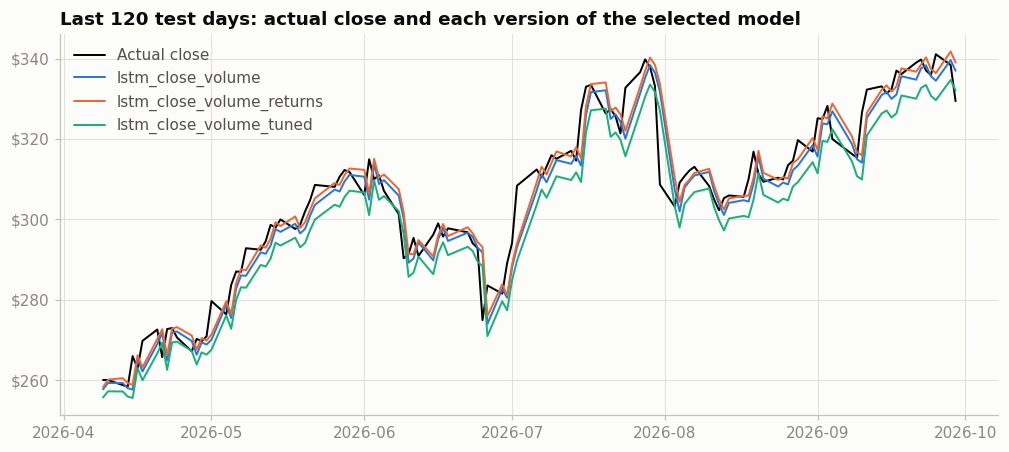

In [ ]:
df = load_stock_data(start_date=None, verbose=False)
rows = []
for name in VERSIONS:
    artifacts = load_artifacts(config.ARTIFACTS_DIR / name)
    next_day = predict_next_day(artifacts, df)
    replay = simulate_recent(artifacts, df, days=20)
    rows.append({"run": name, "predicted close": next_day["predicted_close"],
                 "predicted change (%)": next_day["predicted_change_pct"],
                 "20-day MAE ($)": replay["error ($)"].abs().mean(),
                 "days predicted too low": int((replay["error ($)"] < 0).sum())})
display(pd.DataFrame(rows).set_index("run").round(2))

fig, ax = plt.subplots(figsize=(11, 4.5))
recent = predict_split(selected.model, selected.data).tail(120)
ax.plot(recent.index, recent["actual"], color="black", label="Actual close")
for (name, result), color in zip(VERSIONS.items(), plotting.SERIES):
    ax.plot(recent.index, predict_split(result.model, result.data).tail(120)["predicted"], color=color, label=name)
ax.set_title("Last 120 test days: actual close and each version of the selected model")
plotting._dollar_axis(ax)
ax.legend(loc="upper left")
plotting.save_figure(fig, "improvements_last120.png")
plt.show()

## Results of the improvements

**Iteration 1, stationary inputs.** With the daily log return, the log volume and its change as inputs, the LSTM trained for 40 epochs (best epoch 30) and reached a validation loss of 0.3880, against 0.3841 for the original. In dollars its validation RMSE is \$2.7175 versus \$2.7048, so by the rule set in advance the **original version went on to the tuning step**. On the test set, reported afterward, the picture is reversed: the new version has a test RMSE of \$4.1574 (MAE \$2.86), the lowest of any network in the project, between the drift baseline (\$4.1520) and the naive baseline (\$4.1577). Its bias is gone: it predicts a rise on 84% of the test days with an average predicted return of +0.10%, the same behaviour it shows on the validation set and the same as the average training return. In the 20-day replay its MAE is \$3.87 versus \$3.97, and it predicts \$330.16 (+0.23%) for September 30, 2026.

**Iteration 2, hyperparameter tuning.** The 20 trials on the original inputs reached validation losses between 0.3837 and 0.3870. The best trial (64 units, no dropout, learning rate 0.0028, batch size 64) retrained to a validation loss of 0.3839 and a validation RMSE of \$2.7040, less than a tenth of a cent better than the original. On the test set it is the worst version: RMSE \$5.08, MAE \$3.83, a replay MAE of \$7.09 and a predicted fall of 1.85% for September 30, 2026. It predicts a fall on 95% of the test days with an average predicted return of -0.87%.

| Version | Val RMSE | Test RMSE | Test days predicted up | Replay MAE |
|---|---|---|---|---|
| Original (price and volume levels) | \$2.7048 | \$4.2377 | 5.9% | \$3.97 |
| Tuned original | \$2.7040 | \$5.0840 | 4.8% | \$7.09 |
| Stationary inputs | \$2.7175 | \$4.1574 | 84.2% | \$3.87 |
| Naive baseline | \$2.7110 | \$4.1577 | - | - |
| Random walk + drift | \$2.7147 | \$4.1520 | - | - |

**Why.** A model that always predicts the average training return (0 in scaled units) has a validation Huber loss of 0.3865. Every version in this notebook, and every trial of the search, lies within 0.003 of that floor: none of them has learned a pattern in the returns, and the spread of their predictions is a tenth of the spread of the real returns. The three versions differ only in how they behave when the inputs leave the training range. With price levels as inputs, the validation prices (2.5 to 4.7 training standard deviations) are far less of a stretch than the test prices (3.8 to 9.1), so the drift of the output only appears on the test set, and the tuned version, with no dropout and a higher learning rate, drifts the most. With returns as inputs the ranges are the same in every period, so the model behaves on the test set exactly as it did on the validation set.

**Conclusion.** Under the rule set in advance the tuned original is the best version, and it is the worst on the test set, while the stationary-input version, rejected on validation, is the only one that generalizes. The lesson is about the evaluation protocol, not the networks: a single validation period that sits closer to the training range than the deployment period cannot detect an extrapolation problem. Even so, no version beats the drift baseline, because none has learned more than the average return, so the deployment decision from notebook 05 (do not deploy) is unchanged. The next iteration should change how versions are chosen, for example with a rolling-origin (walk-forward) evaluation whose folds reach prices as far from training as deployment will, and keep the success criterion of beating the drift baseline.